In [3]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
import torchvision

Cifar10 dataset

In [4]:
import torchvision.transforms as transforms
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010)),
])

train_dataset = torchvision.datasets.CIFAR10(root='/content/',train=True, download=True, transform=transform_train)
test_dataset = torchvision.datasets.CIFAR10(root="./content/", train=False, download=True, transform=transform_test)
classes = train_dataset.classes
classes

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

STL-10 Dataset

In [ ]:
import torchvision.transforms as transforms
from torch.utils.data import random_split
transform_train = transforms.Compose([
    transforms.RandomCrop(96, padding=12),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize((0.4467, 0.4398, 0.4066),(0.2603, 0.2566, 0.2713)),
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4467, 0.4398, 0.4066),(0.2603, 0.2566, 0.2713)),
])

dataset = torchvision.datasets.STL10(root='./content/',split="train", download=True, transform=transform_train)
train_dataset, test_dataset = random_split(
    dataset,
    [4000, 1000],
    generator=torch.Generator().manual_seed(42)
)

In [ ]:
mean = torch.tensor((0.4467, 0.4398, 0.4066))
std  = torch.tensor((0.2603, 0.2566, 0.2713))
images, target = train_dataset[27]
img = images.permute(1, 2, 0)
img = img * std + mean
print(img.shape)
plt.imshow(img)
plt.axis("off")
plt.show()

ImageNet100 Dataset

In [2]:
!pip install -q datasets

In [3]:
from datasets import load_dataset

train_dataset = load_dataset("clane9/imagenet-100", split="train")
test_dataset = load_dataset("clane9/imagenet-100", split="validation")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/7.87k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/17 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/17 [00:00<?, ?it/s]

data/train-00000-of-00017.parquet:   0%|          | 0.00/505M [00:00<?, ?B/s]

data/train-00001-of-00017.parquet:   0%|          | 0.00/469M [00:00<?, ?B/s]

... (17 outputs left out)

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Loading dataset shards:   0%|          | 0/17 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/17 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/17 [00:00<?, ?it/s]

In [4]:
import torch
from torchvision.transforms import v2

transform_train = v2.Compose([
    v2.RandomResizedCrop(224, scale=(0.08, 1.0), interpolation=v2.InterpolationMode.BICUBIC),
    v2.RandomHorizontalFlip(p=0.5),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

transform_test = v2.Compose([
    v2.Resize(256, interpolation=v2.InterpolationMode.BICUBIC),
    v2.CenterCrop(224),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [5]:
def apply_train_transform(examples):
    examples["pixel_values"] = [transform_train(img.convert("RGB")) for img in examples["image"]]
    return examples
def apply_test_transform(examples):
    examples["pixel_values"] = [transform_test(img.convert("RGB")) for img in examples["image"]]
    return examples

In [6]:
train_dataset.set_transform(apply_train_transform)
test_dataset.set_transform(apply_test_transform)

American lobster, Northern lobster, Maine lobster, Homarus americanus
(224, 224, 3)


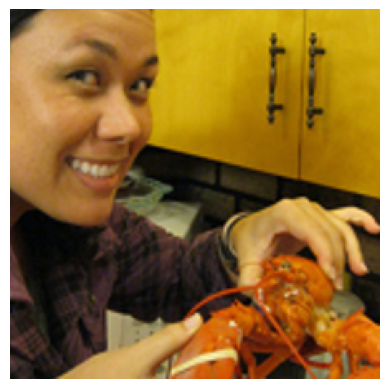

In [7]:
import random

feats = train_dataset.features['label']
classes = feats.names

ix = random.randint(0, len(test_dataset))
x = test_dataset[ix]
img_arr = (x["pixel_values"])
img_arr = img_arr.permute(1, 2, 0).numpy()

mean=np.array([0.485, 0.456, 0.406])
std=np.array([0.229, 0.224, 0.225])
img_arr = img_arr * std + mean
img_arr = np.clip(img_arr, 0, 1)

print(classes[x["label"]])
print(img_arr.shape)
plt.imshow(img_arr)
plt.axis('off')
plt.show()

In [8]:
len(classes)

100

In [ ]:
import os
os.rename("/kaggle/working/62_checkpoint_emb_768", "/kaggle/working/62_checkpoint_emb_768.pth")

In [25]:
class Patching(nn.Module):

    def __init__(self, in_channels, patch_size, image_size, dim):
        super().__init__()
        assert image_size % patch_size == 0
        self.projection = nn.Conv2d(in_channels=in_channels, out_channels=dim, kernel_size=patch_size, stride=patch_size, padding=0)
        self.num_patches = (image_size//patch_size)**2

    def forward(self, x):
        x = self.projection(x)
        return x.flatten(2).transpose(1,2)

In [26]:
class Block(nn.Module):

    def __init__(self, dim, num_heads, mlp_ratio, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, num_heads, batch_first=True, dropout=dropout)
        self.ln2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, dim * mlp_ratio),
            nn.GELU(),
            nn.Linear(dim * mlp_ratio, dim),
            nn.Dropout(dropout)
        )

    def forward(self, x, return_attn=False):
        a, aw = self.attn(self.ln1(x), self.ln1(x), self.ln1(x), need_weights=return_attn, average_attn_weights=True)
        x = x + a
        x = x + self.mlp(self.ln2(x))
        # print(aw)
        return x, aw

In [27]:
class VIT(nn.Module):

    def __init__(self,dim, num_classes, img_size=32, patch_size=4, in_channels=3, depth=12, num_heads=12, mlp_ratio=4):
        super().__init__()
        scale = 0.02
        self.patch = Patching(in_channels, patch_size,img_size, dim)
        num_patches = self.patch.num_patches
        self.cls_token = nn.Parameter(torch.randn(1, 1, dim) * scale)
        self.pos_emb = nn.Parameter(torch.randn(1, num_patches + 1, dim) * scale )
        self.blocks = nn.ModuleList([
            Block(dim, num_heads, mlp_ratio) for _ in range(depth)
        ])
        self.ln = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, num_classes)

    def forward(self, x, return_attn=False):
        x = self.patch(x)
        cls = self.cls_token.expand(x.size(0), -1, -1)
        x = torch.cat([cls, x], dim=1)
        # print(self.pos_emb)
        x = x + self.pos_emb
        A = []
        for blk in self.blocks:
            x, aw = blk(x, return_attn=return_attn)
            if return_attn:
                A.append(aw)
        x = self.ln(x)
        cls_token = x[:, 0,:]
        logits = self.head(cls_token)
        if return_attn:
            return logits, A
        return logits

In [28]:
len(train_dataset)

50000

In [16]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [36]:
import os
CHECKPOINT_PATH = "/kaggle/working/36_checkpoint_emb192.pth"

def load_checkpoint(model, optimizer, filename=CHECKPOINT_PATH):
    start_epoch = 0
    train_lossi = []
    test_lossi = []
    metrics_history = {
        'test_acc': [],
        'test_precision': [],
        'test_recall': [],
        'test_f1': []
    }
    best_test_loss = float('inf')

    if os.path.exists(filename):
        print(f"checkpoint exists...")
        checkpoint = torch.load(filename, map_location=device)

        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        start_epoch = checkpoint['epoch']

        train_lossi = checkpoint.get('train_lossi', [])
        test_lossi = checkpoint.get('test_lossi', [])
        best_test_loss = checkpoint.get('best_test_loss', float('inf'))
        metrics_history = checkpoint.get('metrics_history', metrics_history)

        print(f"resumed from epoch {start_epoch}")
    else:
        print("No checkpoint found.")

    return start_epoch, train_lossi, test_lossi, best_test_loss, metrics_history

def save_checkpoint(model, optimizer, epoch, train_lossi, test_lossi, best_test_loss, metrics_history, filename=CHECKPOINT_PATH):
    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'train_lossi': train_lossi,
        'test_lossi': test_lossi,
        'best_test_loss': best_test_loss,
        'metrics_history': metrics_history
    }
    torch.save(checkpoint, filename)
    print(f"checkpoint saved at epoch {epoch} to '{filename}'")

In [30]:
# os.remove(CHECKPOINT_PATH)

In [31]:
def collator(batch):
    pixel_values = torch.stack([item["pixel_values"] for item in batch])

    labels = torch.tensor([item["label"] for item in batch], dtype=torch.long)

    return {
        "pixel_values": pixel_values,
        "labels": labels
    }


In [32]:
from torch.utils.data import DataLoader
import os
cores_avail = os.cpu_count()
print(cores_avail)
BATCH_SIZE = 128
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=cores_avail,
    pin_memory=True,
    # collate_fn=collator
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=cores_avail,
    pin_memory=True,
    # collate_fn=collator
)
len(train_dataset)

4


50000

In [ ]:
# images, labels = next(iter(train_loader)).values()
# images.shape

torch.Size([128, 3, 224, 224])

In [33]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [37]:
import torch.optim as optim
import torch.amp as amp
import os

emb = 192
vit_classifier = VIT(
    dim=emb,
    num_classes=len(classes),
    img_size=32,
    patch_size=4,
    depth=6,
    num_heads=3,
    mlp_ratio=4
).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(vit_classifier.parameters(), lr=3e-4, weight_decay=0.05)
scaler = amp.GradScaler('cuda')
start_epoch, train_lossi, test_lossi, best_test_loss, metrics_history = load_checkpoint(vit_classifier, optimizer, filename=CHECKPOINT_PATH)

print(f"Current History Length: {len(train_lossi)}")
print(f"Best Test Loss: {best_test_loss}")

checkpoint exists...
resumed from epoch 36
Current History Length: 36
Best Test Loss: 0.5718325357648391


In [18]:
%pip install -q torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 47.4 MB/s eta 0:00:00


In [19]:
from torchmetrics import Precision, Recall, F1Score, Accuracy

num_classes = len(classes)
acc_metric = Accuracy(task="multiclass", num_classes=num_classes, average="macro").to(device)
precision_metric = Precision(task='multiclass', num_classes=num_classes, average="macro").to(device)
recall_metric = Recall(task='multiclass', num_classes=num_classes, average="macro").to(device)
f1score_metric = F1Score(task='multiclass', num_classes=num_classes, average="macro").to(device)

acc_tr = acc_metric.compute()
precision_tr = precision_metric.compute()
recall_tr = recall_metric.compute()
f1score_tr = f1score_metric.compute()

/usr/local/lib/python3.12/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: The ``compute`` method of metric MulticlassAccuracy was called before the ``update`` method which may lead to errors, as metric states have not yet been updated.
  warnings.warn(*args, **kwargs)
/usr/local/lib/python3.12/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: The ``compute`` method of metric MulticlassPrecision was called before the ``update`` method which may lead to errors, as metric states have not yet been updated.
  warnings.warn(*args, **kwargs)
/usr/local/lib/python3.12/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: The ``compute`` method of metric MulticlassRecall was called before the ``update`` method which may lead to errors, as metric states have not yet been updated.
  warnings.warn(*args, **kwargs)
/usr/local/lib/python3.12/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: The ``compute`` method of metric MulticlassF1Score was c

In [22]:
epochs = 50
def train_func():
    global best_test_loss
    for epoch in range(start_epoch, epochs):
        vit_classifier.train()
        running_loss = torch.tensor(0.0, device=device)
        epoch_loss = torch.tensor(0.0, device=device)
        for batch_idx, (images, targets) in enumerate(train_loader):
            images = images.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()

            with amp.autocast('cuda'):
                logits = vit_classifier(images, return_attn=False)
                loss = criterion(logits, targets)

            _, pred_tr = logits.max(1)

            acc_metric.update(pred_tr, targets)
            precision_metric.update(pred_tr, targets)
            recall_metric.update(pred_tr, targets)
            f1score_metric.update(pred_tr, targets)

            scaler.scale(loss).backward()

            scaler.step(optimizer)
            scaler.update()

            running_loss += loss
            epoch_loss += loss

        avg_train_loss = epoch_loss / len(train_loader)
        train_lossi.append(avg_train_loss.item())

        acc_tr = acc_metric.compute()
        precision_tr = precision_metric.compute()
        recall_tr = recall_metric.compute()
        f1score_tr = f1score_metric.compute()

        print(f"After Epoch [{epoch+1}/{epochs}]")
        print(f"TRAIN STATS step [{batch_idx+1}/{len(train_loader)}]\nloss: {avg_train_loss:.4f},"
        f"accuracy: {acc_tr:.4f}, precision: {precision_tr:.4f}, recall: {recall_tr:.4f}, f1_score: {f1score_tr:.4f}")
        running_loss = 0.0


        acc_metric.reset()
        precision_metric.reset()
        recall_metric.reset()
        f1score_metric.reset()

        vit_classifier.eval()
        test_loss = 0.0

        with torch.no_grad():
            for images, targets in test_loader:
                images, targets = images.to(device), targets.to(device)
                with amp.autocast('cuda'):
                    logits = vit_classifier(images)
                    loss = criterion(logits, targets)
                test_loss += loss.item()
                _, predicted = logits.max(1)

                acc_metric.update(preds=predicted, target=targets)
                precision_metric.update(preds=predicted, target=targets)
                recall_metric.update(preds=predicted, target=targets)
                f1score_metric.update(preds=predicted, target=targets)

        avg_test_loss = test_loss / len(test_loader)
        test_acc = acc_metric.compute().item()
        test_precision = precision_metric.compute().item()
        test_recall = recall_metric.compute().item()
        test_f1 = f1score_metric.compute().item()

        metrics_history['test_acc'].append(test_acc)
        metrics_history['test_precision'].append(test_precision)
        metrics_history['test_recall'].append(test_recall)
        metrics_history['test_f1'].append(test_f1)
        test_lossi.append(avg_test_loss)


        print(f"TEST STATS\nloss: {avg_test_loss:.4f},"
        f"accuracy: {test_acc:.4f}, precision: {test_precision:.4f}, recall: {test_recall:.4f}, f1_score: {test_f1:.4f}")

        if avg_test_loss <= best_test_loss:
            best_test_loss = avg_test_loss
            save_checkpoint(vit_classifier, optimizer, epoch + 1, train_lossi, test_lossi, best_test_loss, metrics_history, filename=CHECKPOINT_PATH)

        acc_metric.reset()
        precision_metric.reset()
        recall_metric.reset()
        f1score_metric.reset()

In [ ]:
train_func()

After Epoch [26/50]
TRAIN STATS step [391/391]
loss: 0.7627,accuracy: 0.7266, precision: 0.7256, recall: 0.7266, f1_score: 0.7260
TEST STATS
loss: 0.7359,accuracy: 0.7450, precision: 0.7531, recall: 0.7450, f1_score: 0.7424
After Epoch [27/50]
TRAIN STATS step [391/391]
loss: 0.6326,accuracy: 0.7745, precision: 0.7740, recall: 0.7745, f1_score: 0.7742
TEST STATS
loss: 0.6697,accuracy: 0.7684, precision: 0.7699, recall: 0.7684, f1_score: 0.7675
After Epoch [28/50]
TRAIN STATS step [391/391]
loss: 0.5853,accuracy: 0.7916, precision: 0.7911, recall: 0.7916, f1_score: 0.7913
TEST STATS
loss: 0.6343,accuracy: 0.7858, precision: 0.7863, recall: 0.7858, f1_score: 0.7841
After Epoch [29/50]
TRAIN STATS step [391/391]
loss: 0.5554,accuracy: 0.8008, precision: 0.8004, recall: 0.8008, f1_score: 0.8006
TEST STATS
loss: 0.6515,accuracy: 0.7754, precision: 0.7757, recall: 0.7754, f1_score: 0.7735
After Epoch [30/50]
TRAIN STATS step [391/391]
loss: 0.5250,accuracy: 0.8125, precision: 0.8121, recall:

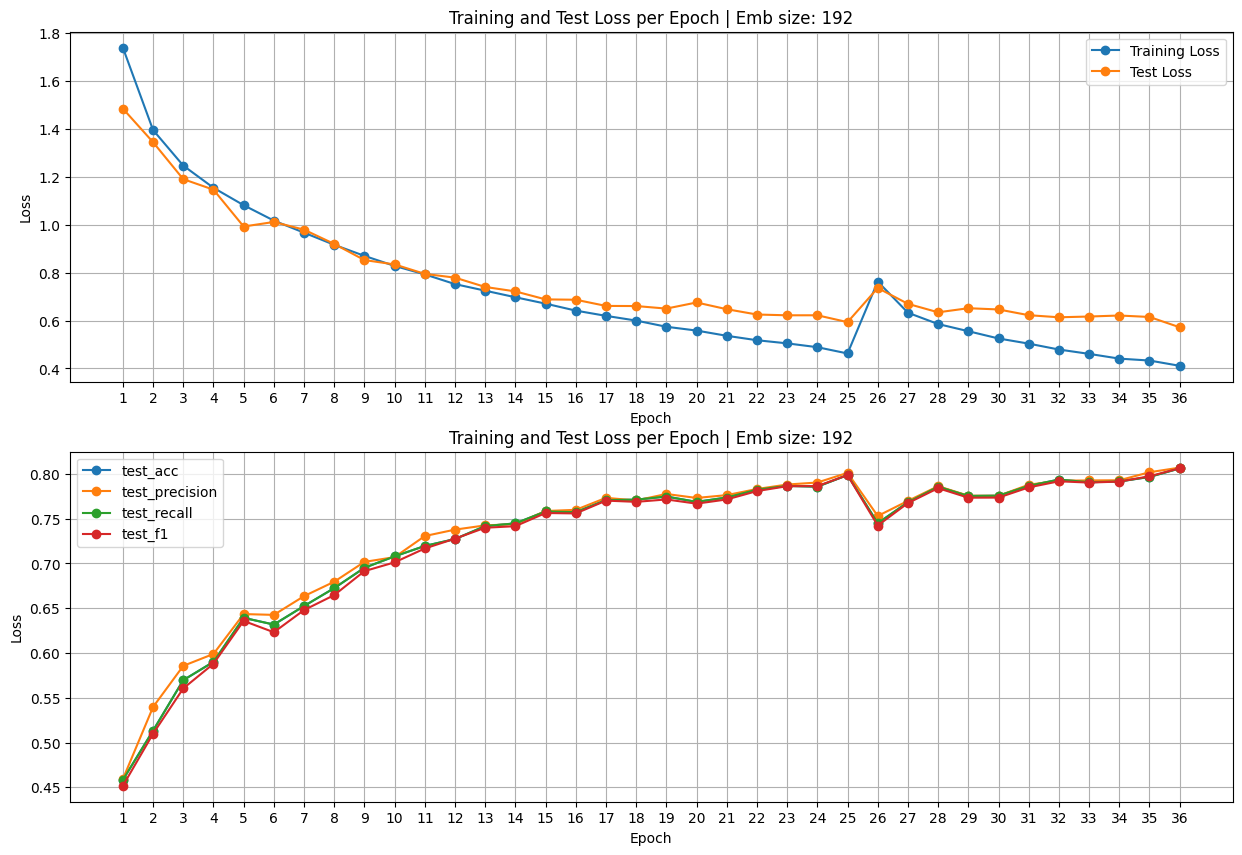

In [38]:
epochs_range = range(1, len(train_lossi) + 1)

fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(15, 10))

ax1.plot(epochs_range, train_lossi, label='Training Loss', marker='o')
ax1.plot(epochs_range, test_lossi, label='Test Loss', marker='o')
for i in metrics_history.keys():
    ax2.plot(epochs_range, metrics_history[i], label=i, marker='o')

for ax in (ax1, ax2):
    ax.set_title(f'Training and Test Loss per Epoch | Emb size: {emb}')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.legend()
    ax.grid(True)
    ax.set_xticks(epochs_range)
plt.show()

In [ ]:
import torch.nn.functional as F
probs = F.softmax(logits, -1)
probs

In [127]:
def plot_tensor_img(img):
    img = img.permute(1,2,0).cpu().numpy()
    mean = np.array([0.4914, 0.4822, 0.4465])
    std = np.array([0.2023, 0.1994, 0.2010])

    img_display = std * img + mean
    img_display = np.clip(img_display, 0, 1)
    return img_display

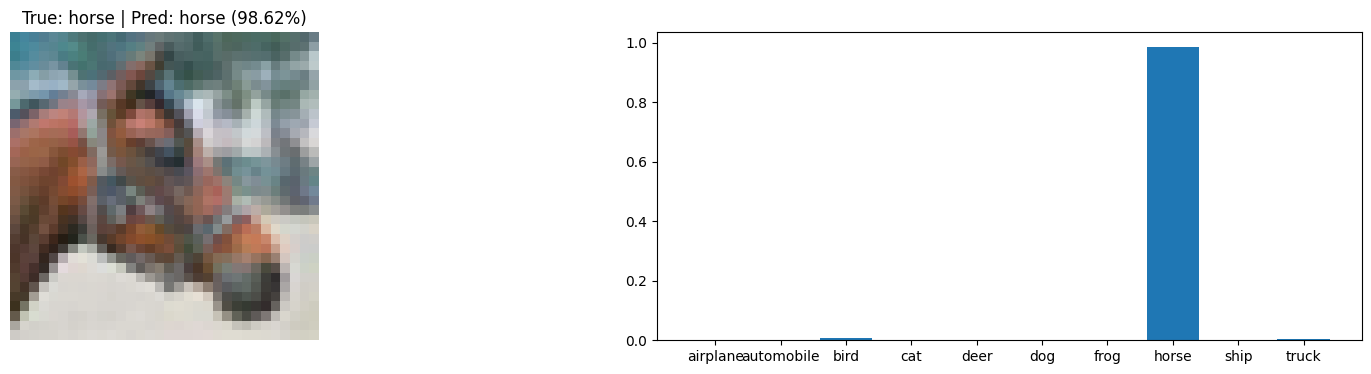

In [128]:
import torch.nn.functional as F
import random
test_imgs, test_targets = next(iter(test_loader))
idx = random.randint(0, len(test_targets) - 1)
input_tensor = test_imgs[idx].unsqueeze(0).to(device)

vit_classifier.eval()
with torch.no_grad():
    logits = vit_classifier(input_tensor)
    probs = F.softmax(logits, dim=-1)
    pred_idx = torch.argmax(probs, dim=-1).item()
    conf = probs[0][pred_idx].item()

true_label = classes[test_targets[idx]]
pred_label = classes[pred_idx]

img_display = plot_tensor_img(test_imgs[idx])

fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(20,4))

ax1.imshow(img_display)
ax1.set_title(f"True: {true_label} | Pred: {pred_label} ({conf:.2%})")
ax1.axis('off')

probs.shape
y = probs.cpu().view(10).detach().numpy()
ax2.bar(classes, y)
plt.show()

In [214]:
import torch

def attn_rollout_func(attentions):
    attn_rollout = []
    dev = attentions[0].device
    I = torch.eye(attentions[0].shape[-1], device=dev)
    prod = I
    for attn_map in attentions:
        prod = prod @ (attn_map + I)
        prod = prod / prod.sum(dim=-1, keepdim=True)
        attn_rollout.append(prod)

    return torch.stack(attn_rollout)


def attn_rollout_heatmaps(attn_matrices, img_size, num_patches):
    attn_rollouts = attn_rollout_func(attn_matrices)
    attn_rollouts.shape
    
    attn_map = attn_rollouts[-1]
    
    cls_attention = attn_map[0, 0, 1:].cpu().numpy()
    side_len = int(np.sqrt(num_patches))
    cls_attention = cls_attention.reshape(side_len, side_len)
    
    # Normalize
    cls_attention = (cls_attention - cls_attention.min()) / (cls_attention.max() - cls_attention.min())
    
    # Resize and Blur
    cls_attention_resized = Image.fromarray((cls_attention * 255).astype(np.uint8)).resize((img_size, img_size), resample=Image.BICUBIC)
    hm_no_blur =np.array(cls_attention_resized) / 255.0
    cls_attention_resized = cls_attention_resized.filter(ImageFilter.GaussianBlur(radius=4))
    heatmap = np.array(cls_attention_resized) / 255.0
    
    return heatmap, hm_no_blur

actual class: bird
pred class: bird


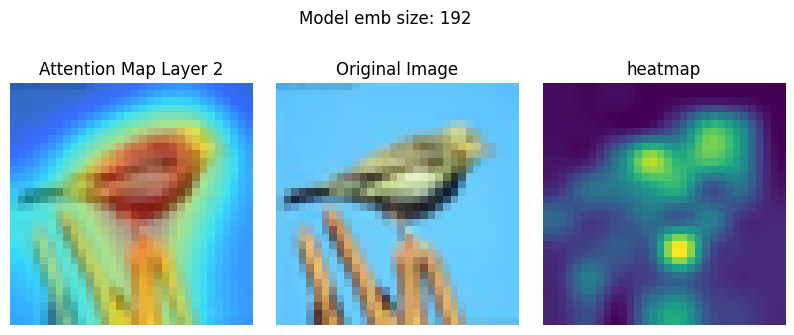

In [222]:
import torch.nn.functional as F
import random
from PIL import Image,ImageFilter
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)
np.random.seed(42)
# random.seed(42)

imgs, targets= next(iter(test_loader))
for idx in range(0, len(imgs)):
    idx = random.randint(0, len(imgs)-1)
    input_tensor = imgs[idx].unsqueeze(0).to(device)

    vit_classifier.eval()
    with torch.no_grad():
        logits, A = vit_classifier(input_tensor,return_attn=True)
        probs = F.softmax(logits, dim=-1)
        pred_idx = torch.argmax(probs, dim=-1).item()
        conf = probs[0][pred_idx].item()
    if classes[targets[idx]] == classes[pred_idx]:
        break

print("actual class:",classes[targets[idx]])
print("pred class:",classes[pred_idx])

img_display = plot_tensor_img(imgs[idx])
DISPLAY_SIZE = (256, 256)
img_pil = Image.fromarray((img_display * 255).astype(np.uint8))
img_display_upscaled = img_pil.resize(DISPLAY_SIZE, resample=Image.BICUBIC)

num_attn_maps = len(A)
num_cols=3
num_of_patches=64
img_size=32
num_rows = 1

h1, h2 = attn_rollout_heatmaps(A, img_size, num_of_patches)

fig, (ax1, ax2, ax3) = plt.subplots(num_rows, num_cols, figsize=(10, 4))
plt.suptitle(f"Model emb size: {emb}")


ax1.imshow(img_display)
ax1.imshow(h1, cmap='jet', alpha=0.45)
ax1.set_title(f'Attention Map Layer {i+1}')
ax1.axis('off')

ax2.imshow(img_display)
ax2.set_title('Original Image')
ax2.axis('off')

ax3.imshow(h2)
ax3.set_title('heatmap')
ax3.axis('off')

plt.subplots_adjust(wspace=0.1, hspace=0.3)
plt.show()

In [87]:

def get_per_layer_predictions(model, input_tensor):

    model.eval()
    layer_logits = []

    def hook_fn(module, input_args, output):
        if isinstance(output, tuple):
            hidden_states = output[0]
        else:
            hidden_states = output

        cls_token = hidden_states[:, 0, :]

        with torch.no_grad():
            logit = model.head(model.ln(cls_token))

        layer_logits.append(logit)

    handles = []
    for block in model.blocks:
        handle = block.register_forward_hook(hook_fn)
        handles.append(handle)

    with torch.no_grad():
        final_logits = model(input_tensor)

    for handle in handles:
        handle.remove()

    return final_logits, layer_logits

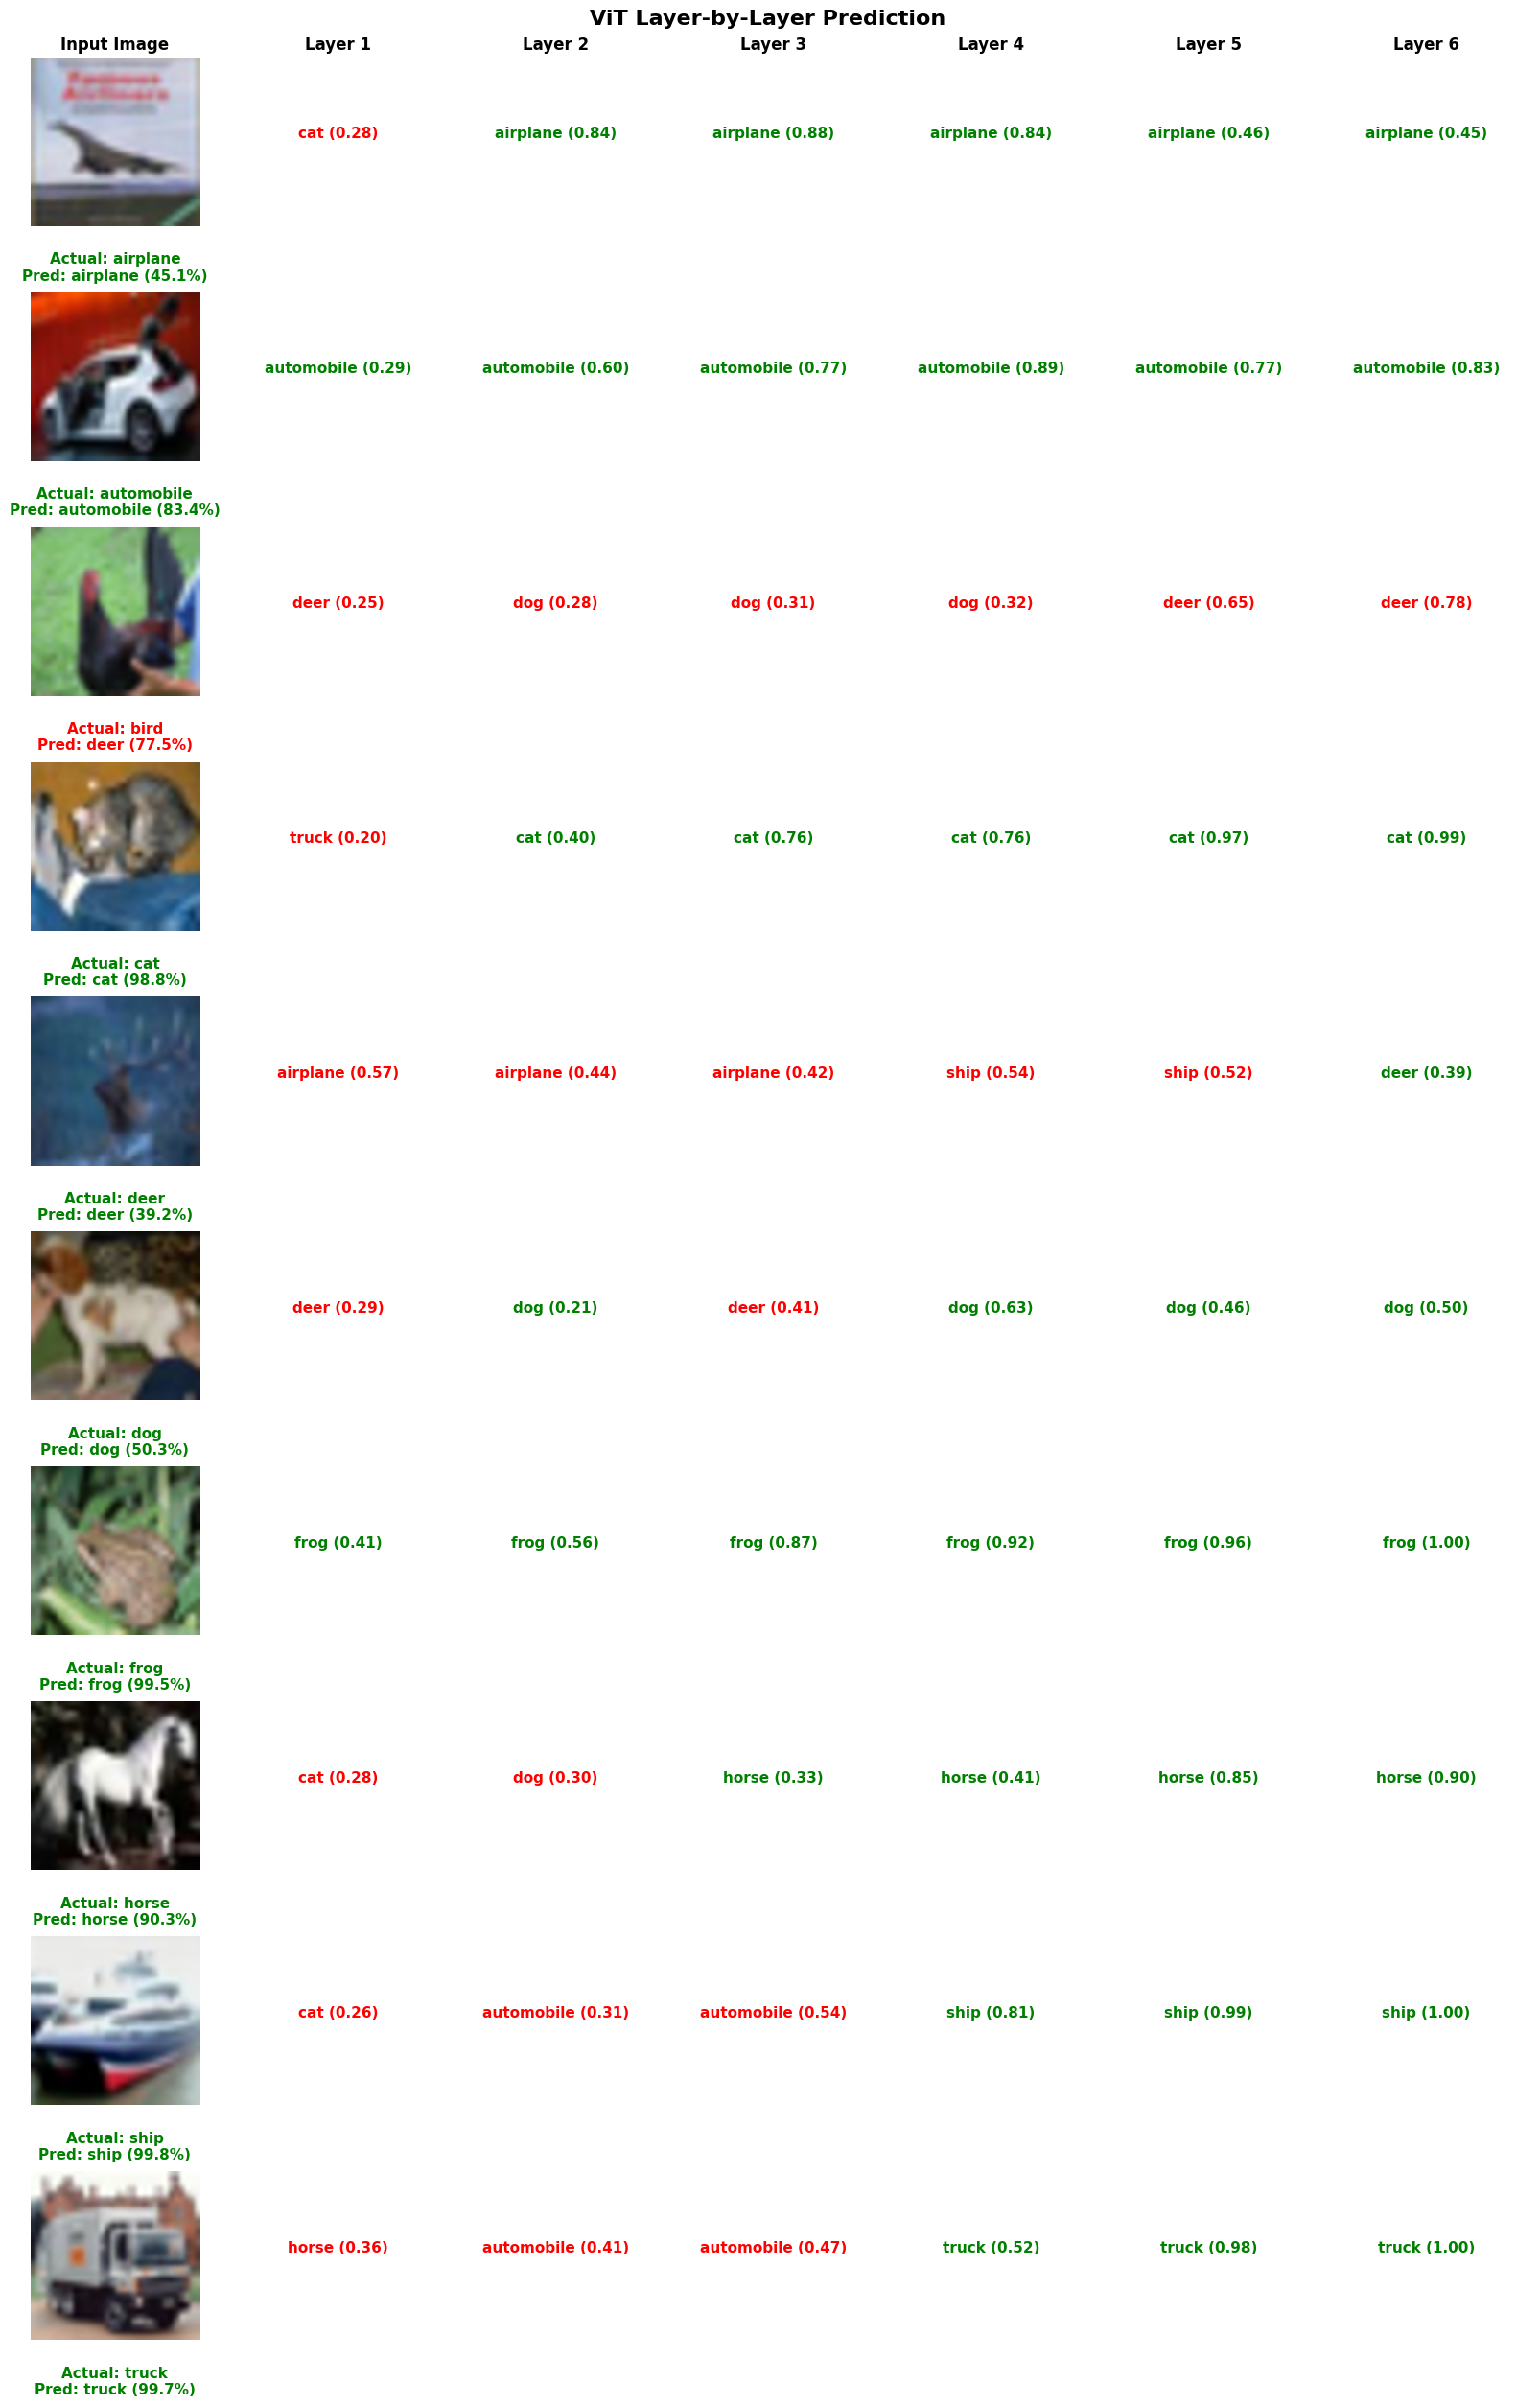

In [255]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch.nn.functional as F
import random
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)
np.random.seed(42)
random.seed(42)

subsets = [return_class_images(class_idx, 1) for class_idx in range(10)]
# for idx, subset in enumerate(subsets):
#     print(subset[0][0].shape)
num_rows = 10
fig, axes = plt.subplots(num_rows, 7, figsize=(16, 2.5 * num_rows), constrained_layout=True)
fig.suptitle("ViT Layer-by-Layer Prediction", fontsize=16, weight='bold')

for class_idx, subset in enumerate(subsets):
    img = subset[0][0]
    input_tensor = img.unsqueeze(0).to(device)

    vit_classifier.eval()
    layer_wise = []

    with torch.no_grad():
        final_logits, layer_logits = get_per_layer_predictions(vit_classifier, input_tensor)
        for layer in layer_logits:
            probs = F.softmax(layer, dim=-1)
            pred_idx_layer = torch.argmax(probs, dim=-1).item()
            conf_layer = probs[0][pred_idx_layer].item()

            layer_wise.append((pred_idx_layer, conf_layer))

        final_probs = F.softmax(final_logits, dim=-1)
        pred_idx = torch.argmax(final_probs, dim=-1).item()
        conf = final_probs[0][pred_idx].item()

    actual_class = classes[class_idx]
    final_class = classes[pred_idx]

    img_display = plot_tensor_img(img)

    DISPLAY_SIZE = (256, 256)
    img_pil = Image.fromarray((img_display * 255).astype(np.uint8))
    img_display_upscaled = img_pil.resize(DISPLAY_SIZE, resample=Image.BICUBIC)

    ax_img = axes[class_idx, 0]
    ax_img.imshow(img_display_upscaled)
    ax_img.axis('off')

    is_final_correct = (final_class == actual_class)
    title_color = 'green' if is_final_correct else 'red'

    if class_idx == 0:
        ax_img.set_title("Input Image", fontsize=12, weight='bold')

    ax_img.text(0.5, -0.15, f"Actual: {actual_class}\nPred: {final_class} ({conf*100:.1f}%)",
                fontsize=11, weight='bold', color=title_color, ha='center', va='top', transform=ax_img.transAxes)

    for i in range(6):
        ax = axes[class_idx, i + 1]

        pred_class_idx, conf_val = layer_wise[i]
        pred_class_name = classes[pred_class_idx]

        is_correct = (pred_class_name == actual_class)
        text_color = 'green' if is_correct else 'red'

        if class_idx == 0:
            ax.set_title(f"Layer {i+1}", fontsize=12, weight='bold')

        ax.text(0.5, 0.55, f"{pred_class_name} ({conf_val:.2f})", fontsize=11, weight='semibold', color=text_color, ha='center', va='center')
        ax.axis('off')

plt.show()

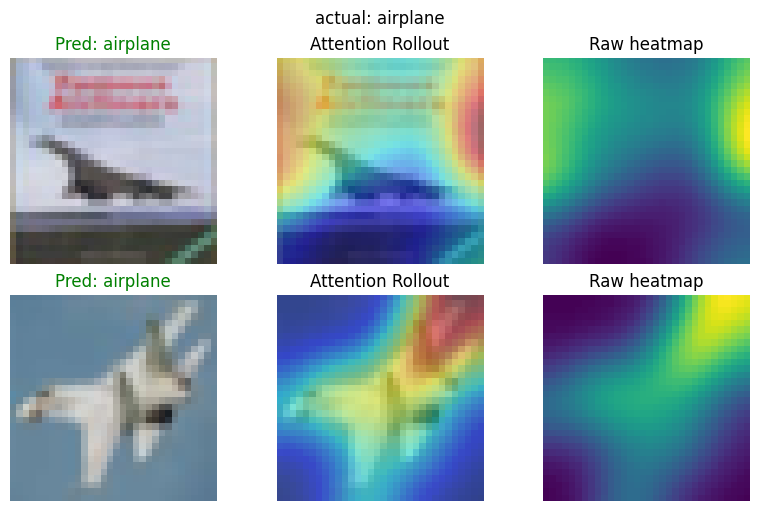

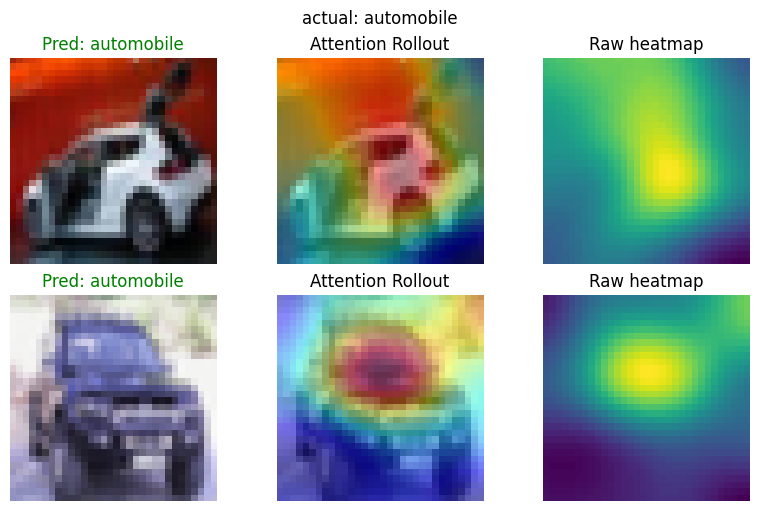

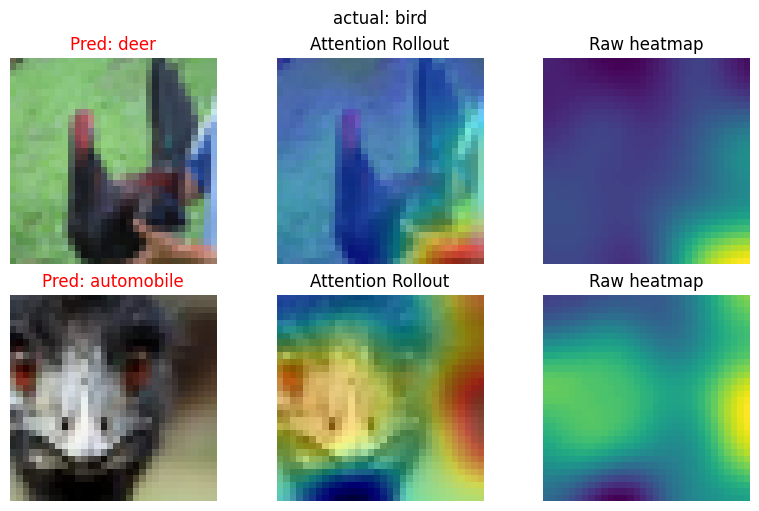

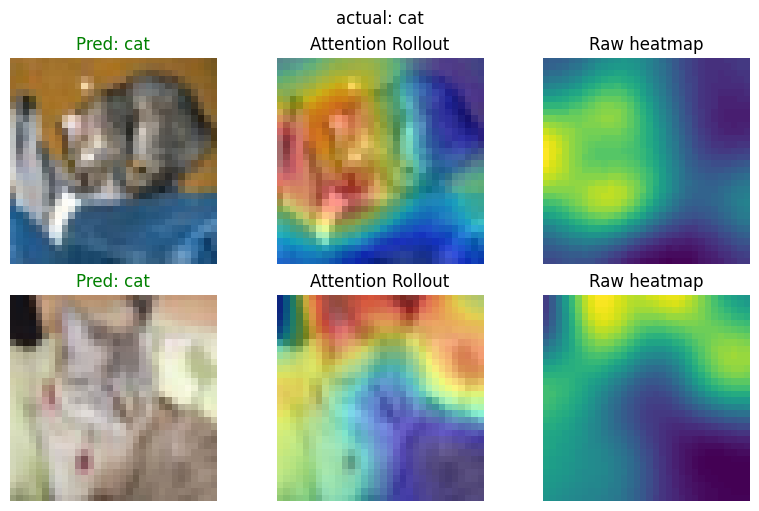

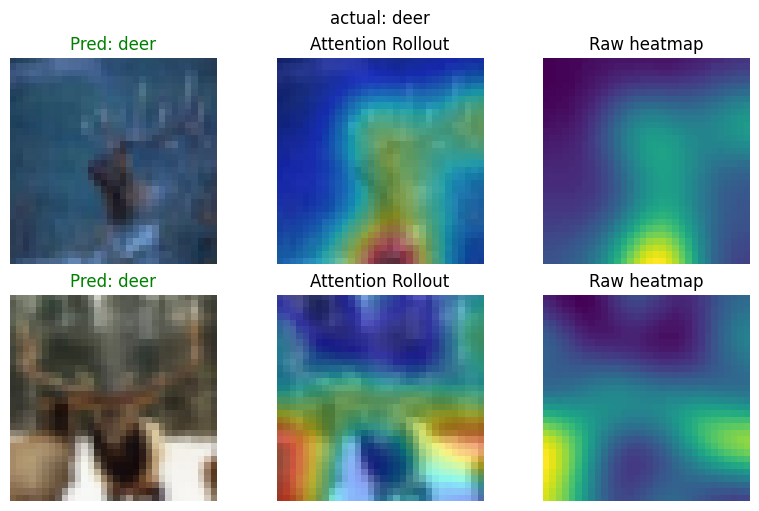

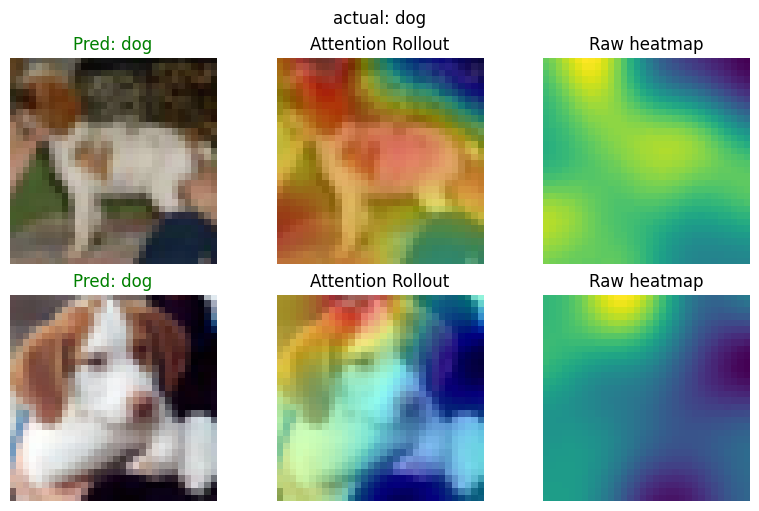

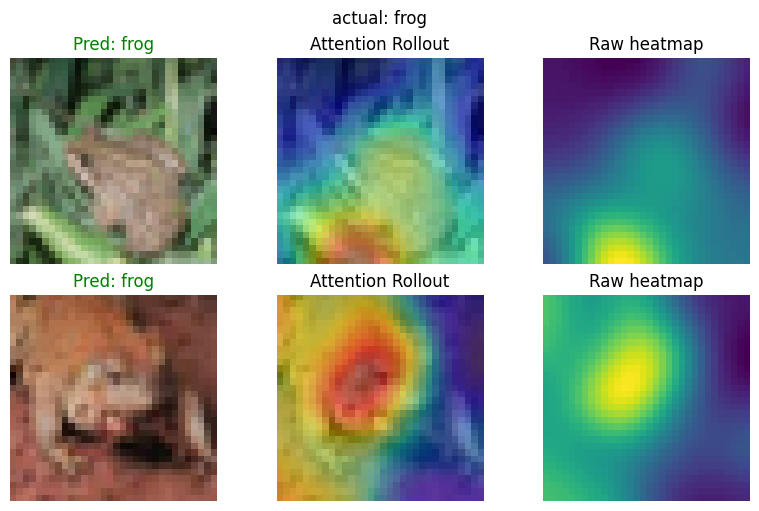

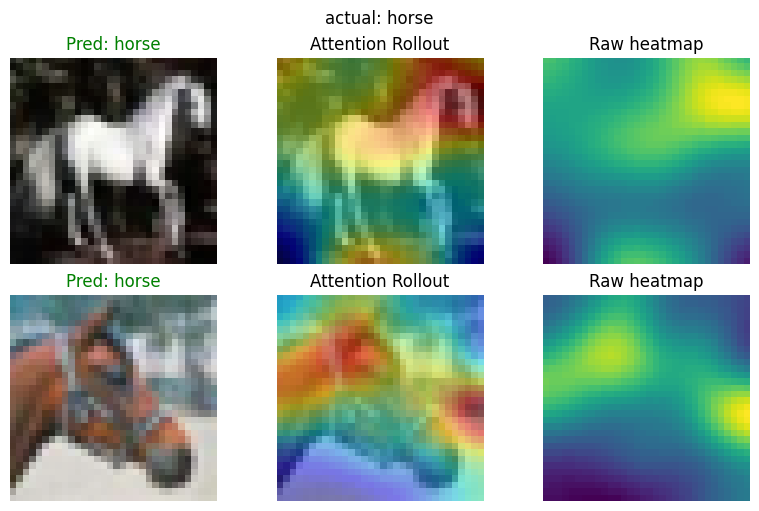

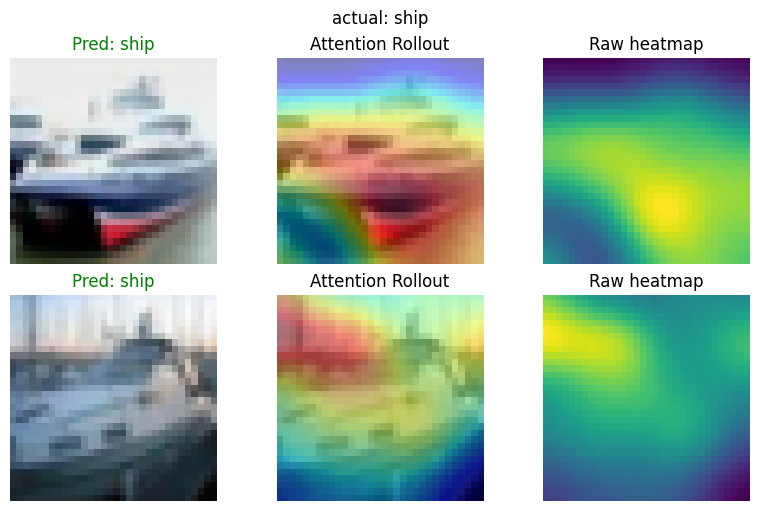

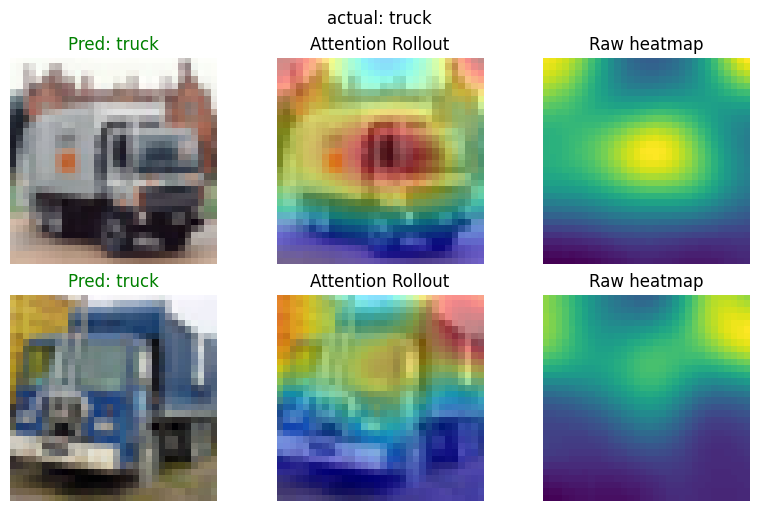

In [240]:
from torch.utils.data  import Subset
def return_class_images(target_class_idx, num_images):
    targets = torch.tensor(test_dataset.targets)
    class_indices = (targets == target_class_idx).nonzero(as_tuple=True)[0]
    subset = Subset(test_dataset, class_indices[:num_images])
    return subset


def get_preds(img):
    input_tensor = img.unsqueeze(0).to(device)
    
    vit_classifier.eval()
    layer_wise = []
    
    with torch.no_grad():
        final_logits, A = vit_classifier(input_tensor, return_attn=True)
        final_probs = F.softmax(final_logits, dim=-1)
        pred_idx = torch.argmax(final_probs, dim=-1).item()
        conf = final_probs[0][pred_idx].item()
    return classes[pred_idx], A

num_imgs=2
num_cols = 3
for class_idx in range(10):
    fig, axes = plt.subplots(num_imgs, num_cols, figsize=(8,5), layout="constrained")

    subset = return_class_images(class_idx, num_imgs)
    
    fig.suptitle(f"actual: {classes[class_idx]}")
    for i, v in enumerate(subset):
        pred_class, A = get_preds(v[0])

        h1, _ = attn_rollout_heatmaps(A, 32, 64)
        img_display = plot_tensor_img(v[0])

        text_color = "green" if (pred_class == classes[class_idx]) else "red"

        axes[i][0].set_title(f"Pred: {pred_class}", color=text_color)
        axes[i][0].imshow(img_display)

        axes[i][1].imshow(img_display)
        axes[i][1].imshow(h1, cmap='jet', alpha=0.45)
        axes[i][1].set_title(f'Attention Rollout')

        axes[i][2].set_title(f'Raw heatmap')
        axes[i][2].imshow(h1)
        
        for j in range(num_cols):
            axes[i][j].axis('off')

plt.show()